Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

  Non-Setosa       0.95      1.00      0.98        20
      Setosa       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.98      0.95      0.96        30
weighted avg       0.97      0.97      0.97        30



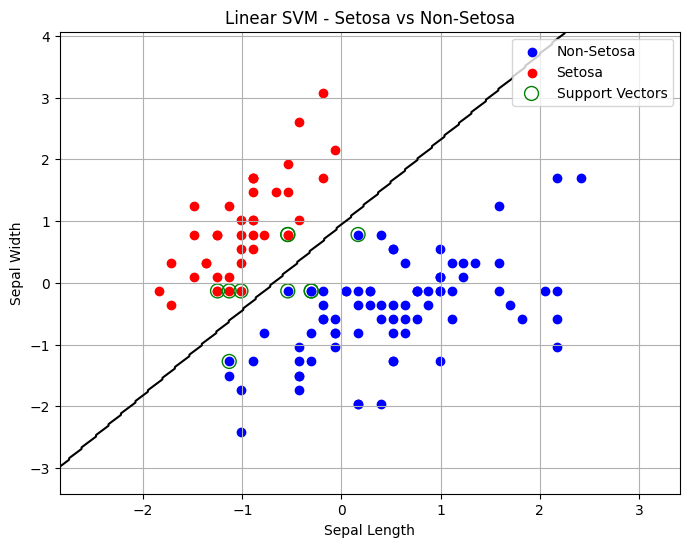


SVM Coefficients: [[-2.11605556  1.53255624]]
SVM Intercept: [-1.44465686]
Support Vectors: 10


In [3]:
# Linear SVM - Iris Dataset
# Setosa vs Non-Setosa

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Load dataset
iris = load_iris()

X = iris.data[:, [0, 1]]   # Sepal Length, Sepal Width
y = (iris.target == 0).astype(int)   # Setosa = 1, Non-Setosa = 0

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Standardize data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Create and train Linear SVM
model = SVC(kernel="linear", C=1.0)
model.fit(X_train, y_train)

# 5. Prediction
y_pred = model.predict(X_test)

# 6. Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# 7. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Setosa", "Setosa"]
))

# 8. Plot decision boundary
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

# Plot points
plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    color="blue",
    label="Non-Setosa"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    color="red",
    label="Setosa"
)

# Decision boundary
plt.contour(xx, yy, Z, levels=[0.5], colors="black")

# Support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="green",
    label="Support Vectors"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Linear SVM - Setosa vs Non-Setosa")
plt.legend()
plt.grid()
plt.show()

# 9. Display SVM parameters
print("\nSVM Coefficients:", model.coef_)
print("SVM Intercept:", model.intercept_)
print("Support Vectors:", len(model.support_vectors_))
